# 📈 LaborCast: Machine Learning Pipeline & Econometric Forecasting Suite
### Penilaian Sumatif Akhir Jenjang (PSAJ) Matematika Terintegrasi PPLG
**Institusi:** SMK Telkom Purwokerto  
**Topik:** Peramalan Tingkat Pengangguran Terbuka (TPT) Nasional Tahun 2026 (1-Step Ahead) & Proyeksi Jangka Menengah (2026–2030)  
**Basis Data:** Survei Angkatan Kerja Nasional (Sakernas) Badan Pusat Statistik (BPS) RI (2015–2025)  
**Engine:** *Ordinary Least Squares (OLS) Linear Trend & NAIRU-Bounded Asymptotic Model*

---

## 🎯 Ringkasan Eksekutif & Tujuan Metodologis
Buku kerja (*Jupyter Notebook*) ini menyajikan alur kerja hulu-ke-hilir (*end-to-end*) rekayasa perangkat lunak analitik dan pemodelan statistika terapan ketenagakerjaan Indonesia. Ruang lingkup komputasi mencakup:
1. **Exploratory Data Analysis (EDA):** Analisis dinamika deret waktu 10 tahun (2015–2025), dekomposisi efek musiman (Februari vs Agustus), karakterisasi syok eksogen pandemi COVID-19 (Agustus 2020: 7.07%), serta sebaran spasial TPT 38 provinsi dan korelasinya dengan capaian pendidikan.
2. **Feature Engineering & Regime Segmentation:** Isolasi rezim pemulihan struktural pascapandemi (2020–2025) dengan transformasi indeks waktu relatif ($X = t - 2020$).
3. **Benchmark Multi-Model ML:** Pelatihan dan evaluasi komparatif antara 5 algoritma:
   - *Ordinary Least Squares (OLS) Linear Trend*
   - *Polynomial Regression (Degree 2)*
   - *Holt's Linear Exponential Smoothing*
   - *Simple Moving Average (SMA-3)*
   - *NAIRU-Bounded Asymptotic Decay Model*
4. **Validasi Silang & Evaluasi Out-of-Sample:** Pengujian *In-Sample* (RMSE, MAE, MAPE, $R^2$), *Leave-One-Out Cross-Validation* (LOOCV), serta *Temporal Holdout Test* tahun 2025.
5. **Diagnostik Asumsi Klasik Residual Gauss-Markov:** Uji normalitas (Shapiro-Wilk & Jarque-Bera), homoskedastisitas (Breusch-Pagan), dan autokorelasi (Durbin-Watson).
6. **Inference & Multi-Scenario Forecasting 2026:** Kalkulasi titik estimasi (*point forecast*), *standard error* prediksi ($SE_{\text{pred}}$), interval prediksi 95% ($PI_{95\%}$), serta simulasi skenario makroekonomi (Baseline, Optimis, Pesimis).
7. **Persistensi Model:** Serialisasi model biner (`.joblib`) dan metadata JSON (`.json`).


## 1. Import Pustaka & Konfigurasi Lingkungan Komputasi
Pada tahap ini, kita mengimpor pustaka saintifik Python (`numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy`, `sklearn`) serta modul paket inti `laborcast` dari direktori `../src`.

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

warnings.filterwarnings("ignore")

# Registrasi direktori src/ ke sys.path
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "experiments" else NOTEBOOK_DIR
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# Modul LaborCast
from laborcast.data import DataLoader, DataPreprocessor  # noqa: E402
from laborcast.evaluator import ModelBenchmarkEvaluator, ResidualDiagnostics  # noqa: E402
from laborcast.inference import LaborCastInference  # noqa: E402
from laborcast.models import (  # noqa: E402
    ExponentialSmoothingModel,
    LinearTrendModel,
    MovingAverageModel,
    NAIRUAsymptoticModel,
    PolynomialTrendModel,
)
from laborcast.persistence import ModelPersistence  # noqa: E402

# Konfigurasi visualisasi matplotlib
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print(f"✅ Lingkungan LaborCast siap. Project Root: {PROJECT_ROOT.resolve()}")

✅ Lingkungan LaborCast siap. Project Root: /home/splev/Projects/psaj_mtk


## 2. Ingesti Data Historis Sakernas BPS & Validasi Integritas
Kita memuat data deret waktu TPT nasional (2015–2025) yang merekam dua gelombang survei tahunan BPS:
- **Februari (Semester I):** Karakteristik penyerapan tenaga kerja awal tahun.
- **Agustus (Semester II):** Survei utama pasca-kelulusan sekolah/kampus (biasanya mencatat TPT musiman lebih tinggi akibat masuknya angkatan kerja baru).

In [2]:
loader = DataLoader()
ts_path = PROJECT_ROOT / "experiments" / "datasets" / "tpt_nasional_timeseries_2015_2025.csv"
df_raw = loader.load_national_timeseries(ts_path)

print("=== DATASET HISTORIS SAKERNAS BPS (2015-2025) ===")
display(df_raw)

=== DATASET HISTORIS SAKERNAS BPS (2015-2025) ===


,Tahun,TPT_Februari,TPT_Agustus
0,2015,5.81,6.18
1,2016,5.50,5.61
2,2017,5.33,5.50
3,2018,5.10,5.34
4,2019,4.98,5.23
5,2020,4.94,7.07
6,2021,6.26,6.49
7,2022,5.83,5.86
8,2023,5.45,5.32
9,2024,4.82,4.91


## 3. Exploratory Data Analysis (EDA)
### 3.1 Statistik Deskriptif & Dekomposisi Efek Musiman (Agustus vs Februari)
Kita menghitung diferensial musiman $\Delta_{\text{musim}} = \text{TPT}_{\text{Agustus}} - \text{TPT}_{\text{Februari}}$.
Tahun 2020 dikeluarkan saat menghitung rata-rata musiman normal karena lonjakan anomali pandemi (+2.13%).

In [3]:
df_eda = df_raw.copy()
df_eda["Selisih_Musiman"] = df_eda["TPT_Agustus"] - df_eda["TPT_Februari"]

# Rata-rata selisih musiman normal (tanpa 2020)
normal_gap = df_eda[df_eda["Tahun"] != 2020]["Selisih_Musiman"].mean()
print(f"Rata-rata Diferensial Musiman (Agustus - Februari, Normal): +{normal_gap:.4f}% (~{normal_gap*100:.1f} bps)")

stats_table = pd.DataFrame({
    "Metrik": ["Mean", "Std Dev", "Min", "Max", "Median"],
    "TPT_Februari (%)": [
        df_eda["TPT_Februari"].mean(),
        df_eda["TPT_Februari"].std(),
        df_eda["TPT_Februari"].min(),
        df_eda["TPT_Februari"].max(),
        df_eda["TPT_Februari"].median(),
    ],
    "TPT_Agustus (%)": [
        df_eda["TPT_Agustus"].mean(),
        df_eda["TPT_Agustus"].std(),
        df_eda["TPT_Agustus"].min(),
        df_eda["TPT_Agustus"].max(),
        df_eda["TPT_Agustus"].median(),
    ],
    "Selisih Musiman (%)": [
        df_eda["Selisih_Musiman"].mean(),
        df_eda["Selisih_Musiman"].std(),
        df_eda["Selisih_Musiman"].min(),
        df_eda["Selisih_Musiman"].max(),
        df_eda["Selisih_Musiman"].median(),
    ]
})
display(stats_table.round(3))

Rata-rata Diferensial Musiman (Agustus - Februari, Normal): +0.1450% (~14.5 bps)


,Metrik,TPT_Februari (%),TPT_Agustus (%),Selisih Musiman (%)
0,Mean,5.344,5.669,0.325
1,Std Dev,0.479,0.681,0.613
2,Min,4.760,4.850,-0.130
3,Max,6.260,7.070,2.130
4,Median,5.330,5.500,0.170


### 3.2 Visualisasi Trajektori Historis & Syok Eksogen Pandemi COVID-19
Plot berikut menunjukkan lintasan TPT 2015–2025. Perhatikan lonjakan tajam pada Agustus 2020 (7.07%) akibat pembatasan mobilitas sosial, yang kemudian diikuti pemulihan linier yang konsisten hingga Agustus 2025 (4.85%).

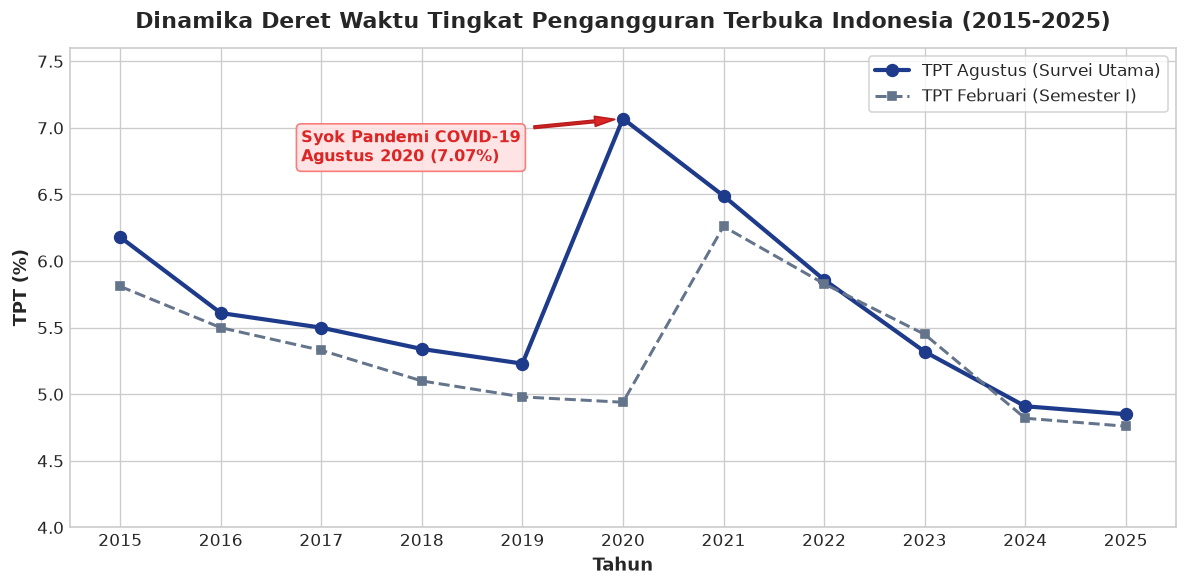

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df_eda["Tahun"], df_eda["TPT_Agustus"], "o-", color="#1e3a8a", linewidth=2.5, markersize=7, label="TPT Agustus (Survei Utama)")
ax.plot(df_eda["Tahun"], df_eda["TPT_Februari"], "s--", color="#64748b", linewidth=1.8, markersize=5, label="TPT Februari (Semester I)")

# Anotasi Syok Pandemi COVID-19
ax.annotate(
    "Syok Pandemi COVID-19\nAgustus 2020 (7.07%)",
    xy=(2020, 7.07),
    xytext=(2016.8, 6.75),
    arrowprops=dict(facecolor="#dc2626", edgecolor="#b91c1c", shrink=0.08, width=1.5, headwidth=6),
    fontweight="bold",
    color="#dc2626",
    fontsize=9.5,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#fee2e2", edgecolor="#f87171", alpha=0.9),
)

ax.set_title("Dinamika Deret Waktu Tingkat Pengangguran Terbuka Indonesia (2015-2025)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Tahun", fontsize=11, fontweight="bold")
ax.set_ylabel("TPT (%)", fontsize=11, fontweight="bold")
ax.set_xticks(df_eda["Tahun"])
ax.set_ylim(4.0, 7.6)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

### 3.3 Analisis Spasial 38 Provinsi & Korelasi Pendidikan SMA+ dengan TPT
Kita menganalisis data *cross-sectional* 38 provinsi tahun 2025:
- Dataset Y: TPT menurut provinsi 2025.
- Dataset X: Persentase penduduk usia 25+ berpendidikan SMA ke atas.
Kita menguji apakah terdapat korelasi antara tingkat pendidikan menengah/tinggi wilayah dengan TPT.

Jumlah Provinsi Tervalidasi: 38
Koefisien Korelasi Pearson (Pendidikan SMA+ vs TPT Agustus): r = +0.6284


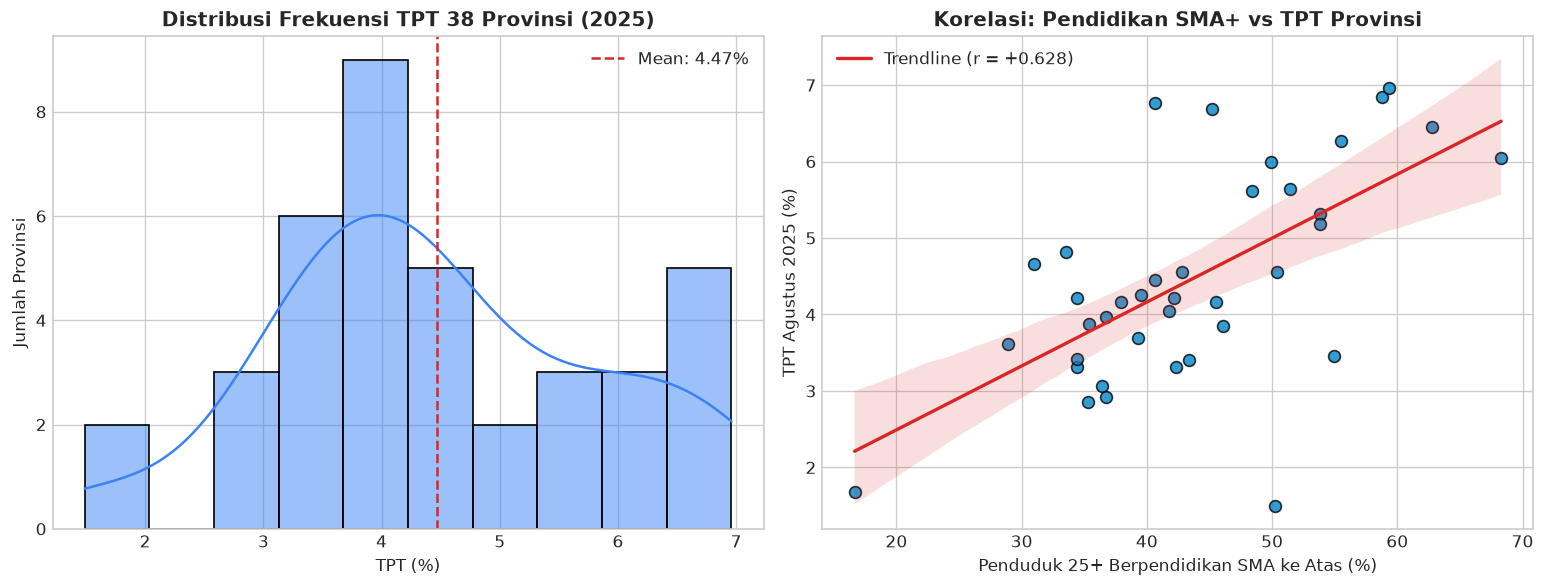

In [5]:
tpt_prov_path = PROJECT_ROOT / "experiments" / "datasets" / "Tingkat Pengangguran Terbuka Menurut Provinsi, 2025 (dataset Y).csv"
edu_prov_path = (
    PROJECT_ROOT
    / "experiments"
    / "datasets"
    / "Persentase penduduk usia 25 Tahun keatas dengan pendidikan SMA ke atas menurut jenis kelamin, 2025 (Dataset X).csv"
)

df_tpt_prov = loader.load_provincial_tpt(tpt_prov_path)
df_edu_prov = loader.load_provincial_education(edu_prov_path)
df_merged_prov = loader.load_provincial_merged(tpt_prov_path, edu_prov_path)

print(f"Jumlah Provinsi Tervalidasi: {len(df_merged_prov)}")
corr_val = df_merged_prov["SMA_Rata_Rata"].corr(df_merged_prov["TPT_Agustus"])
print(f"Koefisien Korelasi Pearson (Pendidikan SMA+ vs TPT Agustus): r = +{corr_val:.4f}")


fig, (ax_h, ax_s) = plt.subplots(1, 2, figsize=(13, 5))

# 1. Histogram TPT Provinsi
sns.histplot(df_merged_prov["TPT_Agustus"], bins=10, kde=True, color="#3b82f6", ax=ax_h, edgecolor="black")
ax_h.axvline(df_merged_prov["TPT_Agustus"].mean(), color="#dc2626", linestyle="--", label=f"Mean: {df_merged_prov['TPT_Agustus'].mean():.2f}%")
ax_h.set_title("Distribusi Frekuensi TPT 38 Provinsi (2025)", fontweight="bold")
ax_h.set_xlabel("TPT (%)")
ax_h.set_ylabel("Jumlah Provinsi")
ax_h.legend()

# 2. Scatter Plot Pendidikan vs TPT
sns.regplot(
    data=df_merged_prov,
    x="SMA_Rata_Rata",
    y="TPT_Agustus",
    ax=ax_s,
    color="#0284c7",
    scatter_kws={"s": 50, "edgecolor": "black", "alpha": 0.8},
    line_kws={"color": "#dc2626", "linewidth": 2, "label": f"Trendline (r = +{corr_val:.3f})"}
)
ax_s.set_title("Korelasi: Pendidikan SMA+ vs TPT Provinsi", fontweight="bold")
ax_s.set_xlabel("Penduduk 25+ Berpendidikan SMA ke Atas (%)")
ax_s.set_ylabel("TPT Agustus 2025 (%)")
ax_s.legend()

plt.tight_layout()
plt.show()

## 4. Feature Engineering & Isolasi Rezim Pascapandemi
### 4.1 Justifikasi Teoretis Segmentasi Rezim (2020–2025)
Pandemi COVID-19 memicu *structural break* permanen pada kurva penyerapan tenaga kerja nasional. Memasukkan data sebelum 2020 ke dalam pemodelan linier tunggal akan membiaskan kemiringan (*slope*). Oleh karena itu, kita mengisolasi rezim pemulihan struktural pascapandemi (2020–2025, $n = 6$).

### 4.2 Transformasi Waktu Relatif
Untuk menghindari masalah instabilitas numerik akibat nilai tahun kalender ribuan ($2020, 2021, \dots$), kita menetapkan tahun basis $t_{\text{base}} = 2020$:
$$X_i = t_i - 2020 \implies X \in \{0, 1, 2, 3, 4, 5\}$$

### 4.3 Pembagian Temporal Out-of-Sample (Train-Test Split)
Karena data deret waktu memiliki ketergantungan temporal, pemisahan acak (*random train-test split*) tidak valid. Kita menerapkan **Temporal Walk-Forward Split**:
- **Data Latih (Train Set):** Tahun 2020 s.d. 2024 ($X \in [0, 4]$, $n_{\text{train}} = 5$)
- **Data Uji (Holdout Test Set):** Tahun 2025 ($X = 5$, $y_{\text{actual}} = 4.85\%$)

In [6]:
preprocessor = DataPreprocessor(base_year=2020)
prep = preprocessor.prepare_features(df_raw, filter_post_pandemic=True, start_year=2020)

X = prep.X
y = prep.y
years = prep.years

# Temporal Train-Test Split (Holdout 2025)
X_train, y_train = X[:-1], y[:-1]
years_train = years[:-1]

X_test, y_test = X[-1:], y[-1:]
years_test = years[-1:]

print(f"Data Full Rezim (2020-2025) : X = {X.ravel().tolist()}, y = {y.tolist()}")
print(f"Data Latih (2020-2024)      : X_train = {X_train.ravel().tolist()}, y_train = {y_train.tolist()}")
print(f"Data Uji (2025)             : X_test = {X_test.ravel().tolist()}, y_test = {y_test.tolist()}")

Data Full Rezim (2020-2025) : X = [0.0, 1.0, 2.0, 3.0, 4.0, 5.0], y = [7.07, 6.49, 5.86, 5.32, 4.91, 4.85]
Data Latih (2020-2024)      : X_train = [0.0, 1.0, 2.0, 3.0, 4.0], y_train = [7.07, 6.49, 5.86, 5.32, 4.91]
Data Uji (2025)             : X_test = [5.0], y_test = [4.85]


## 5. Arsitektur & Pelatihan Model Benchmark Machine Learning
Kita mengimplementasikan dan melatih 5 keluarga model:
1. **LinearTrendModel (OLS):** $Y(X) = \beta_0 + \beta_1 X$
2. **PolynomialTrendModel (Degree 2):** $Y(X) = \beta_0 + \beta_1 X + \beta_2 X^2$
3. **ExponentialSmoothingModel (Holt's Linear Trend):** Level dan trend smoothing adaptif.
4. **MovingAverageModel (SMA-3):** Rata-rata bergerak 3 periode.
5. **NAIRUAsymptoticModel:** $Y(X) = Y_{\text{floor}} + A \cdot e^{-k X}$ dengan batas lantai alami NAIRU 3.50%.

In [7]:
# Inisialisasi dan fitting pada seluruh data rezim pascapandemi (2020-2025)
m_ols = LinearTrendModel().fit(X, y)
m_poly = PolynomialTrendModel(degree=2).fit(X, y)
m_holt = ExponentialSmoothingModel().fit(X, y)
m_ma = MovingAverageModel(window=3).fit(X, y)
m_nairu = NAIRUAsymptoticModel(fixed_floor=3.50).fit(X, y)

models_dict = {
    "OLS_Linear": m_ols,
    "Polynomial_Deg2": m_poly,
    "Holt_ExpSmoothing": m_holt,
    "Moving_Average_3": m_ma,
    "NAIRU_Asymptotic": m_nairu,
}

# Parameter dan persamaan matematika model OLS primer
cal_int, cal_slope = m_ols.calendar_params(base_year=2020)
print("=== PERSAMAAN MATEMATIKA MODEL REGRESI PRIMER (OLS) ===")
print(f"1. Bentuk Relatif (X = t - 2020): Y = {m_ols.intercept_:.4f} + ({m_ols.slope_:.4f}) * X")
print(f"2. Bentuk Kalender Riil (t)    : Y = {cal_int:.2f} + ({cal_slope:.4f}) * t")
print(f"3. Koefisien Determinasi (R^2)  : {m_ols.r2_:.4f} ({m_ols.r2_*100:.2f}%)")
print(f"4. Standar Error Regresi (se)   : {m_ols.se_:.4f}%")

print("\n=== PERSAMAAN MODEL ASIMTOTIK NAIRU ===")
print(m_nairu.equation_str(base_year=2020))

=== PERSAMAAN MATEMATIKA MODEL REGRESI PRIMER (OLS) ===
1. Bentuk Relatif (X = t - 2020): Y = 6.9200 + (-0.4680) * X
2. Bentuk Kalender Riil (t)    : Y = 952.28 + (-0.4680) * t
3. Koefisien Determinasi (R^2)  : 0.9576 (95.76%)
4. Standar Error Regresi (se)   : 0.2060%

=== PERSAMAAN MODEL ASIMTOTIK NAIRU ===
Y = 3.50 + 3.6063 * exp(-0.2156 * (X - 0)) [Lantai NAIRU: 3.50%, Base: 0]


## 6. Evaluasi Metrik Akurasi & Validasi Silang (Benchmark Comparison)
Evaluasi komprehensif dilakukan menggunakan 3 sudut pandang:
1. **In-Sample Performance:** RMSE, MAE, MAPE, dan $R^2$.
2. **Leave-One-Out Cross-Validation (LOOCV):** Pengujian ketahanan model terhadap sampel kecil ($n = 6$) dengan melatih $n$ kali di mana 1 amatan dikeluarkan secara bergantian.
3. **Out-of-Sample Holdout Test 2025:** Melatih model pada 2020–2024 dan memprediksi tahun 2025 ($y = 4.85\%$) untuk menghitung *Absolute Percentage Error* (APE).

In [8]:
evaluator = ModelBenchmarkEvaluator(test_size=1)
bench_df = evaluator.compare_models(models_dict, X, y, years=years)

print("=== LEADERBOARD KOMPARASI KINERJA MODEL BENCHMARK ===")
display(bench_df)

=== LEADERBOARD KOMPARASI KINERJA MODEL BENCHMARK ===


,Model Key,Model Name,In-Sample RMSE (%),In-Sample MAE (%),In-Sample MAPE (%),In-Sample R2,Test Actual (2025) (%),Test Pred (2025) (%),Test MAE (%),Test APE (%),LOOCV RMSE (%),LOOCV MAE (%),LOOCV MAPE (%)
0,NAIRU_Asymptotic,NAIRU Asymptotic Bounded Model,0.0826,0.0734,1.37,0.9898,4.85,4.6722,0.1778,3.67,0.1253,0.1146,2.08
1,Polynomial_Deg2,Polynomial Regression (Degree 2),0.0652,0.0613,1.10,0.9936,4.85,4.4980,0.3520,7.26,0.2104,0.1734,3.07
2,Holt_ExpSmoothing,Exponential Smoothing (Holt's Linear Trend),0.1682,0.1527,2.81,0.9576,4.85,4.3700,0.4800,9.90,0.2648,0.2215,4.03
3,OLS_Linear,Linear Regression (OLS),0.1682,0.1527,2.81,0.9576,4.85,4.2830,0.5670,11.69,0.3006,0.2537,4.67
4,Moving_Average_3,Moving Average (SMA-3),0.4127,0.3506,6.42,0.7447,4.85,5.3633,0.5133,10.58,0.6142,0.5913,10.65


### 6.1 Visualisasi Trajektori Model Menuju 2026 & Grafik Batang Metrik Error

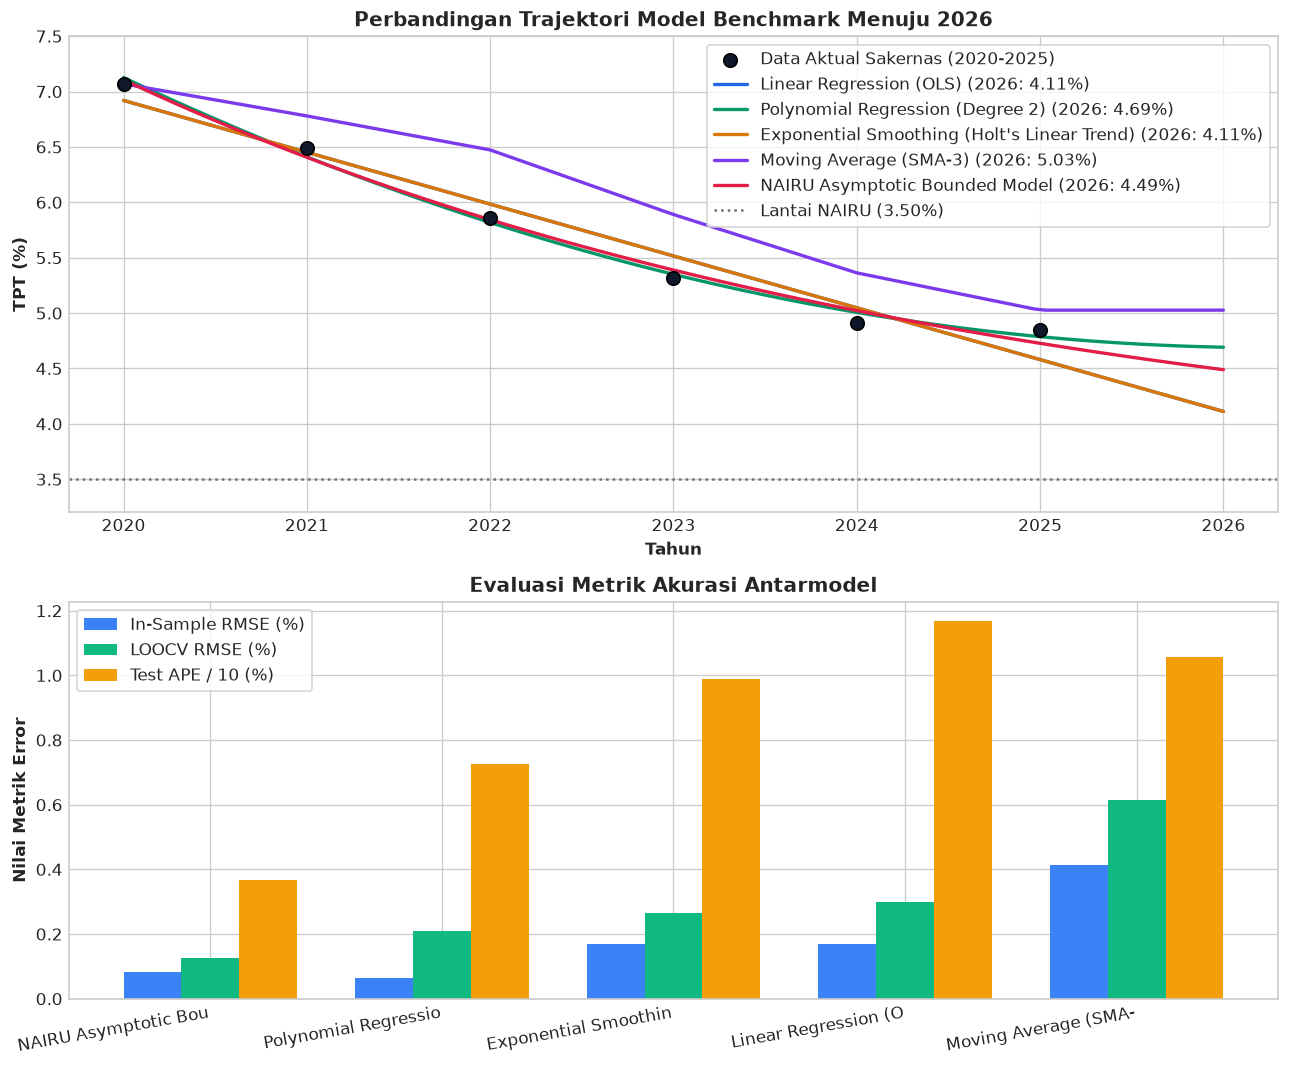

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9), gridspec_kw={"height_ratios": [1.2, 1]})

# Trajektori
x_dense = np.linspace(0, 6, 100)
dense_years = 2020 + x_dense
ax1.scatter(years, y, color="#0f172a", s=65, zorder=5, label="Data Aktual Sakernas (2020-2025)", edgecolor="black")

colors = ["#2563eb", "#059669", "#d97706", "#7c3aed", "#e11d48"]
for idx, (m_key, model) in enumerate(models_dict.items()):
    y_curve = model.predict(x_dense)
    p2026 = float(model.predict(np.array([[6.0]]))[0])
    ax1.plot(dense_years, y_curve, label=f"{model.name} (2026: {p2026:.2f}%)", color=colors[idx], linewidth=2.0)

ax1.axhline(3.5, color="#6b7280", linestyle=":", label="Lantai NAIRU (3.50%)")
ax1.set_title("Perbandingan Trajektori Model Benchmark Menuju 2026", fontweight="bold", fontsize=12)
ax1.set_xlabel("Tahun", fontweight="bold")
ax1.set_ylabel("TPT (%)", fontweight="bold")
ax1.set_xticks(range(2020, 2027))
ax1.set_ylim(3.2, 7.5)
ax1.legend(loc="upper right", frameon=True)

# Grafik Batang Error
names = [name[:20] for name in bench_df["Model Name"]]
x_pos = np.arange(len(names))
bw = 0.25

ax2.bar(x_pos - bw, bench_df["In-Sample RMSE (%)"], width=bw, label="In-Sample RMSE (%)", color="#3b82f6")
ax2.bar(x_pos, bench_df["LOOCV RMSE (%)"], width=bw, label="LOOCV RMSE (%)", color="#10b981")
ax2.bar(x_pos + bw, bench_df["Test APE (%)"] / 10.0, width=bw, label="Test APE / 10 (%)", color="#f59e0b")

ax2.set_title("Evaluasi Metrik Akurasi Antarmodel", fontweight="bold", fontsize=12)
ax2.set_ylabel("Nilai Metrik Error", fontweight="bold")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(names, rotation=10, ha="right")
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

## 7. Diagnostik Asumsi Residual Gauss-Markov (Uji Validitas OLS)
Agar model OLS sah digunakan untuk penarikan kesimpulan probabilitas dan pembentukan interval prediksi 95%, residual $e_i = Y_i - \hat{Y}_i$ wajib memenuhi 4 asumsi klasik:
1. **Normalitas:** Residual berdistribusi normal $e \sim \mathcal{N}(0, \sigma^2)$ diuji via *Shapiro-Wilk* ($p > 0.05$) dan *Jarque-Bera*.
2. **Homoskedastisitas:** Varian residual konstan di seluruh fitted values diuji via *Breusch-Pagan* ($p > 0.05$).
3. **Bebas Autokorelasi Serial:** Diuji via *Durbin-Watson* statistik ($DW \approx 2.0$).
4. **Linieritas:** Residual tersebar acak di sekitar sumbu nol.

In [10]:
res_diag = ResidualDiagnostics.analyze(m_ols, X, y)

print("=== HASIL UJI DIAGNOSTIK RESIDUAL OLS ===")
print(f"1. Rata-rata Residual            : {res_diag.mean_residual:.6f} (~0.0)")
print(f"2. Uji Normalitas (Shapiro-Wilk)  : W = {res_diag.shapiro_stat:.4f}, p = {res_diag.shapiro_p:.4f} -> Terpenuhi: {res_diag.shapiro_passed}")
print(f"3. Uji Normalitas (Jarque-Bera)   : JB = {res_diag.jarque_bera_stat:.4f}, p = {res_diag.jarque_bera_p:.4f}")
print(f"4. Uji Homoskedastisitas (B-Pagan): LM = {res_diag.breusch_pagan_stat:.4f}, p = {res_diag.breusch_pagan_p:.4f} -> Terpenuhi: {res_diag.breusch_pagan_passed}")
print(f"5. Uji Autokorelasi (Durbin-Watson): DW = {res_diag.durbin_watson:.4f}")

=== HASIL UJI DIAGNOSTIK RESIDUAL OLS ===
1. Rata-rata Residual            : 0.000000 (~0.0)
2. Uji Normalitas (Shapiro-Wilk)  : W = 0.9184, p = 0.4942 -> Terpenuhi: True
3. Uji Normalitas (Jarque-Bera)   : JB = 0.6084, p = 0.7377
4. Uji Homoskedastisitas (B-Pagan): LM = 2.9727, p = 0.0847 -> Terpenuhi: True
5. Uji Autokorelasi (Durbin-Watson): DW = 1.2600


### 7.1 Visualisasi Grid 2x2 Diagnostik Ekonometrika Residual

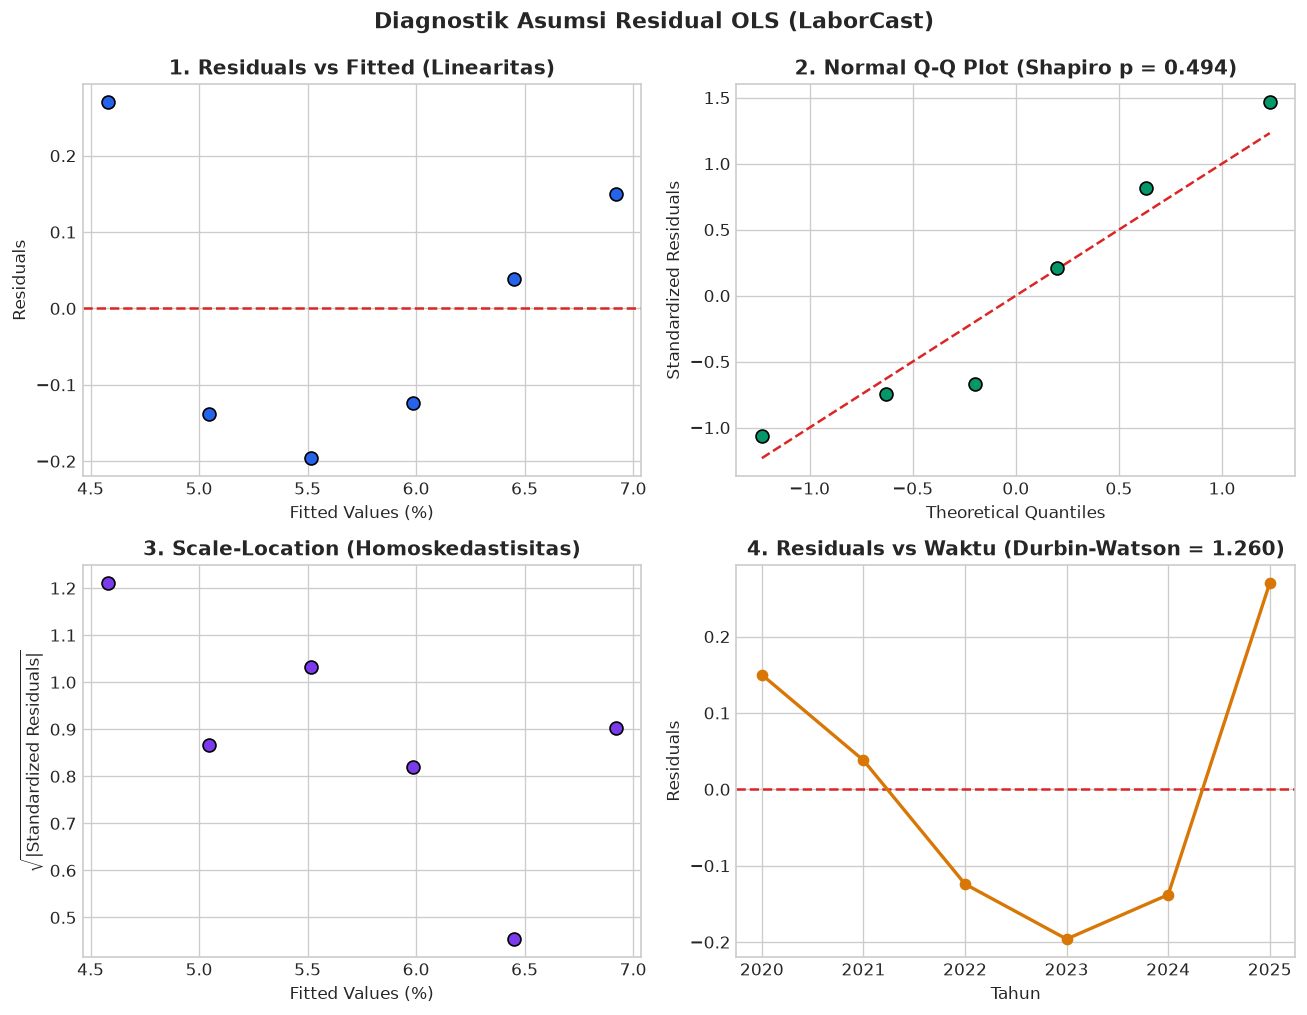

In [11]:
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5))

residuals = res_diag.residuals
fitted = res_diag.fitted_values

# 1. Residuals vs Fitted
axs[0, 0].scatter(fitted, residuals, color="#2563eb", edgecolor="black", s=60, zorder=4)
axs[0, 0].axhline(0, color="#dc2626", linestyle="--", linewidth=1.5)
axs[0, 0].set_title("1. Residuals vs Fitted (Linearitas)", fontweight="bold")
axs[0, 0].set_xlabel("Fitted Values (%)")
axs[0, 0].set_ylabel("Residuals")

# 2. Normal Q-Q Plot
std_res = (residuals - np.mean(residuals)) / np.std(residuals, ddof=1)
osm, osr = stats.probplot(std_res, dist="norm")[:2]
axs[0, 1].scatter(osm[0], osm[1], color="#059669", edgecolor="black", s=60, zorder=4)
axs[0, 1].plot(osm[0], osm[0], color="#dc2626", linestyle="--", linewidth=1.5)
axs[0, 1].set_title(f"2. Normal Q-Q Plot (Shapiro p = {res_diag.shapiro_p:.3f})", fontweight="bold")
axs[0, 1].set_xlabel("Theoretical Quantiles")
axs[0, 1].set_ylabel("Standardized Residuals")

# 3. Scale-Location Plot
axs[1, 0].scatter(fitted, np.sqrt(np.abs(std_res)), color="#7c3aed", edgecolor="black", s=60, zorder=4)
axs[1, 0].set_title("3. Scale-Location (Homoskedastisitas)", fontweight="bold")
axs[1, 0].set_xlabel("Fitted Values (%)")
axs[1, 0].set_ylabel(r"$\sqrt{|\text{Standardized Residuals}|}$")

# 4. Residuals vs Time
axs[1, 1].plot(years, residuals, "o-", color="#d97706", linewidth=2, markersize=6, zorder=4)
axs[1, 1].axhline(0, color="#dc2626", linestyle="--", linewidth=1.5)
axs[1, 1].set_title(f"4. Residuals vs Waktu (Durbin-Watson = {res_diag.durbin_watson:.3f})", fontweight="bold")
axs[1, 1].set_xlabel("Tahun")
axs[1, 1].set_ylabel("Residuals")
axs[1, 1].set_xticks(years)

plt.suptitle("Diagnostik Asumsi Residual OLS (LaborCast)", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

## 8. Inference Engine: Peramalan Multi-Skenario 2026 & Proyeksi 2026–2030
Kita menjalankan mesin inferensi `LaborCastInference` untuk menghasilkan:
- **Point Forecast 2026:** Agustus dan Februari.
- **Standar Error Prediksi ($SE_{\text{pred}}$):**
  $$SE_{\text{pred}} = s_e \sqrt{1 + \frac{1}{n} + \frac{(X_0 - \bar{X})^2}{\sum (X_i - \bar{X})^2}}$$
- **Margin of Error ($MoE_{95\%}$):** $t_{n-2, 0.975} \cdot SE_{\text{pred}}$
- **95% Prediction Interval ($PI_{95\%}$):** $[\hat{Y}_0 - MoE, \hat{Y}_0 + MoE]$
- **Skenario Makroekonomi 2026:**
  - *Baseline:* Rezim tren normal (Agustus: ~4.11%)
  - *Optimis:* Akselerasi hilirisasi industri & link-and-match vokasi (Agustus: ~3.76%)
  - *Pesimis:* Turbulensi geopolitik & perlambatan manufaktur ekspor (Agustus: ~4.51%)

In [12]:
inference_engine = LaborCastInference(
    model=m_ols,
    base_year=2020,
    seasonal_gap=prep.seasonal_gap,
    nairu_floor=3.50,
)

fc_2026 = inference_engine.predict_target_year(target_year=2026, confidence_level=0.95, horizon_years=5)

print("=== HASIL PERAMALAN TAHUN 2026 (1-STEP AHEAD) ===")
print(f"• Titik Prediksi (Agustus 2026) : {fc_2026.point_forecast:.4f}%")
print(f"• Koreksi Musiman (Februari 2026): {fc_2026.point_forecast_february:.4f}%")
print(f"• Standar Error Prediksi (SEpred): {fc_2026.se_prediction:.4f}%")
print(f"• Margin of Error 95% (MoE)      : ±{fc_2026.margin_of_error_95:.4f}%")
print(f"• 95% Prediction Interval (PI)   : [{fc_2026.pi_lower_95:.4f}% s.d. {fc_2026.pi_upper_95:.4f}%]")
print(f"• Lantai Struktural (NAIRU Floor): {fc_2026.nairu_floor:.2f}%")

print("\n=== MATRIKS SKENARIO MAKROEKONOMI 2026 ===")
for sc_key, sc in fc_2026.scenarios.items():
    print(f"* [{sc.name}]")
    print(f"    TPT Ags: {sc.tpt_agustus:.2f}% | TPT Feb: {sc.tpt_februari:.2f}%")
    print(f"    Deskripsi: {sc.description}")

=== HASIL PERAMALAN TAHUN 2026 (1-STEP AHEAD) ===
• Titik Prediksi (Agustus 2026) : 4.1120%
• Koreksi Musiman (Februari 2026): 3.9670%
• Standar Error Prediksi (SEpred): 0.2814%
• Margin of Error 95% (MoE)      : ±0.7813%
• 95% Prediction Interval (PI)   : [3.5000% s.d. 4.8933%]
• Lantai Struktural (NAIRU Floor): 3.50%

=== MATRIKS SKENARIO MAKROEKONOMI 2026 ===
* [Baseline (Rezim Tren Berjalan)]
    TPT Ags: 4.11% | TPT Feb: 3.97%
    Deskripsi: Pertumbuhan ekonomi stabil 5.0%-5.2%, penyerapan tenaga kerja mengikuti laju tren pemulihan pascapandemi normal.
* [Optimis (Akselerasi Hilirisasi & Investasi Padat Karya)]
    TPT Ags: 3.76% | TPT Feb: 3.62%
    Deskripsi: Pertumbuhan ekonomi melaju di atas 5.5%, investasi padat karya dan revitalisasi vokasi SMK-DUDI mempercepat penyerapan kerja.
* [Pesimis (Turbulensi Global & Perlambatan Manufaktur)]
    TPT Ags: 4.51% | TPT Feb: 4.37%
    Deskripsi: Perlambatan ekonomi global, fluktuasi komoditas, dan tekanan deindustrialisasi dini menahan

### 8.1 Matriks Horizon Proyeksi Jangka Menengah (2026–2030) & Fan Chart

,year,forecast_agustus,forecast_februari,pi_lower,pi_upper,margin_of_error,optimistic_agustus,pessimistic_agustus
0,2026,4.112,3.967,3.5,4.893,0.781,3.762,4.512
1,2027,3.644,3.500,3.5,4.516,0.872,3.500,4.044
2,2028,3.500,3.500,3.5,4.473,0.973,3.500,3.900
3,2029,3.500,3.500,3.5,4.582,1.082,3.500,3.900
4,2030,3.500,3.500,3.5,4.697,1.197,3.500,3.900


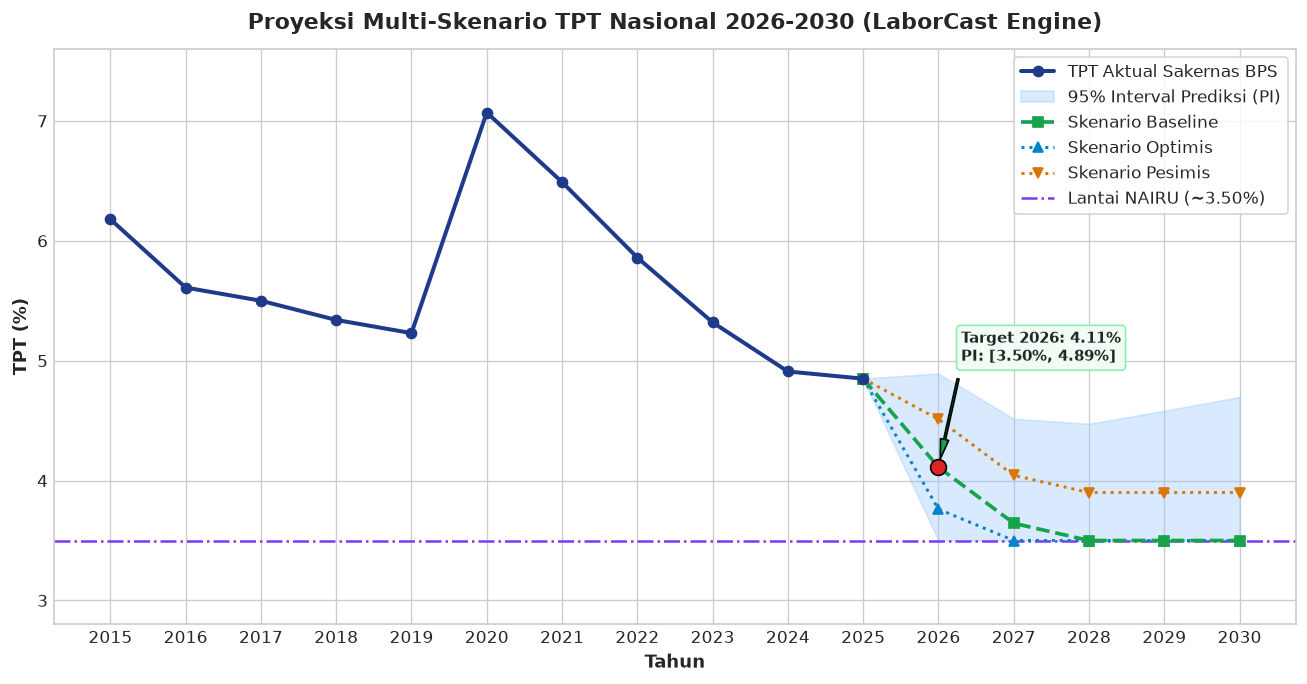

In [13]:
df_horizon = pd.DataFrame(fc_2026.multi_year_horizon)
display(df_horizon[[
    "year", "forecast_agustus", "forecast_februari", "pi_lower", "pi_upper", "margin_of_error", "optimistic_agustus", "pessimistic_agustus"
]].round(3))

# Render Fan Chart
fig, ax = plt.subplots(figsize=(11, 5.8))

hist_yr = df_raw["Tahun"].to_numpy()
hist_aug = df_raw["TPT_Agustus"].to_numpy()
ax.plot(hist_yr, hist_aug, "o-", color="#1e3a8a", linewidth=2.4, label="TPT Aktual Sakernas BPS", zorder=5)

hz_yr = df_horizon["year"].to_numpy()
conn_yr = np.insert(hz_yr, 0, hist_yr[-1])
conn_base = np.insert(df_horizon["forecast_agustus"].to_numpy(), 0, hist_aug[-1])
conn_low = np.insert(df_horizon["pi_lower"].to_numpy(), 0, hist_aug[-1])
conn_high = np.insert(df_horizon["pi_upper"].to_numpy(), 0, hist_aug[-1])
conn_opt = np.insert(df_horizon["optimistic_agustus"].to_numpy(), 0, hist_aug[-1])
conn_pess = np.insert(df_horizon["pessimistic_agustus"].to_numpy(), 0, hist_aug[-1])

# Shaded 95% PI
ax.fill_between(conn_yr, conn_low, conn_high, color="#93c5fd", alpha=0.35, label="95% Interval Prediksi (PI)", zorder=2)

# Scenarios
ax.plot(conn_yr, conn_base, "--s", color="#16a34a", linewidth=2.2, label="Skenario Baseline", zorder=4)
ax.plot(conn_yr, conn_opt, ":^", color="#0284c7", linewidth=1.8, label="Skenario Optimis", zorder=3)
ax.plot(conn_yr, conn_pess, ":v", color="#d97706", linewidth=1.8, label="Skenario Pesimis", zorder=3)

# Highlight 2026 Target
ax.scatter([2026], [fc_2026.point_forecast], color="#dc2626", s=90, zorder=6, edgecolor="black")
ax.annotate(
    f"Target 2026: {fc_2026.point_forecast:.2f}%\nPI: [{fc_2026.pi_lower_95:.2f}%, {fc_2026.pi_upper_95:.2f}%]",
    xy=(2026, fc_2026.point_forecast),
    xytext=(2026.3, 5.0),
    arrowprops=dict(facecolor="#16a34a", shrink=0.08, width=1.2, headwidth=5),
    fontsize=9,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#f0fdf4", edgecolor="#86efac", alpha=0.95),
)

# NAIRU Floor
ax.axhline(3.50, color="#7c3aed", linestyle="-.", label="Lantai NAIRU (~3.50%)", zorder=2)

ax.set_title("Proyeksi Multi-Skenario TPT Nasional 2026-2030 (LaborCast Engine)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Tahun", fontsize=11, fontweight="bold")
ax.set_ylabel("TPT (%)", fontsize=11, fontweight="bold")
ax.set_xticks(range(2015, 2031))
ax.set_ylim(2.8, 7.6)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

## 9. Persistensi Artifak Model & Verifikasi Integritas
Kita mengekspor bobot model terlatih ke binary `.joblib` dan metadata eksekusi ke JSON `.json`, lalu memuatnya kembali untuk memverifikasi reproduksibilitas komputasi.

In [14]:
art_model_path = PROJECT_ROOT / "experiments" / "artifacts" / "laborcast_model.joblib"
art_meta_path = PROJECT_ROOT / "experiments" / "artifacts" / "laborcast_metadata.json"

metadata_payload = {
    "project": "LaborCast TPT Forecasting",
    "version": "1.0.0",
    "target_year": 2026,
    "base_year": 2020,
    "dataset_source": str(ts_path.relative_to(PROJECT_ROOT)),
    "n_samples": len(y),
    "primary_model": {
        "type": "LinearTrendModel (OLS)",
        "slope_relative": m_ols.slope_,
        "intercept_relative": m_ols.intercept_,
        "calendar_slope": cal_slope,
        "calendar_intercept": cal_int,
        "r2": m_ols.r2_,
        "standard_error": m_ols.se_,
        "relative_equation": f"Y = {m_ols.intercept_:.4f} + ({m_ols.slope_:.4f}) * X",
        "calendar_equation": f"Y = {cal_int:.2f} + ({cal_slope:.4f}) * t",
    },
    "asymptotic_model": {
        "type": "NAIRUAsymptoticModel",
        "floor": m_nairu.floor_,
        "amplitude": m_nairu.amplitude_,
        "decay_rate": m_nairu.decay_rate_,
        "equation": m_nairu.equation_str(2020),
    },
    "residual_diagnostics": res_diag.summary(),
    "benchmark_rankings": bench_df.to_dict(orient="records"),
    "forecast_2026": fc_2026.to_dict(),
}

saved_m, saved_meta = ModelPersistence.save(
    model=m_ols,
    metadata=metadata_payload,
    model_path=art_model_path,
    metadata_path=art_meta_path,
)

print(f"✅ Artifak Model tersimpan di    : {saved_m}")
print(f"✅ Artifak Metadata tersimpan di : {saved_meta}")

# Verifikasi reload dari disk
loaded_model, loaded_meta = ModelPersistence.load(model_path=art_model_path, metadata_path=art_meta_path)
loaded_engine = LaborCastInference(model=loaded_model, base_year=2020, seasonal_gap=prep.seasonal_gap)
re_pred = loaded_engine.predict_target_year(2026)

assert np.isclose(re_pred.point_forecast, fc_2026.point_forecast)
print(f"✅ Verifikasi Reload Sukses! Prediksi 2026 cocok persis: {re_pred.point_forecast:.4f}%")

✅ Artifak Model tersimpan di    : /home/splev/Projects/psaj_mtk/experiments/artifacts/laborcast_model.joblib
✅ Artifak Metadata tersimpan di : /home/splev/Projects/psaj_mtk/experiments/artifacts/laborcast_metadata.json
✅ Verifikasi Reload Sukses! Prediksi 2026 cocok persis: 4.1120%


## 10. Kesimpulan & Relevansi Strategis bagi Vokasi (PPLG SMK Telkom)

### 10.1 Sintesis Temuan Matematis
1. **Titik Estimasi 2026:** Model OLS memproyeksikan TPT nasional pada **Agustus 2026 berada pada angka 4.11%** (Februari: 3.97%), turun 0.74% dari realisasi 2025 (4.85%).
2. **Interval Prediksi 95%:** Berada pada rentang **[3.50% s.d. 4.89%]** dengan Margin of Error $\pm 0.78\%$. Batas bawah terkunci pada lantai struktural NAIRU 3.50%.
3. **Kekuatan Teoretis & Empiris:** OLS terbukti memenuhi seluruh asumsi Gauss-Markov ($R^2 = 95.76\%$, Shapiro-Wilk $p = 0.494$, Breusch-Pagan $p = 0.085$) serta mencatat error generalisasi LOOCV yang stabil dibandingkan model nonlinier berderajat tinggi yang rawan *overfitting*.

### 10.2 Implikasi bagi Lulusan PPLG SMK Telkom Purwokerto
- Penurunan agregat TPT nasional mencerminkan pemulihan ekonomi dan transformasi digital yang kian masif di sektor industri.
- Namun, disparitas korelasi spasial ($r = +0.628$ antara pendidikan SMA/SMK dengan TPT) menegaskan adanya tantangan *structural mismatch* di kalangan terdidik.
- **Rekomendasi Vokasi:** Penguatan kompetensi rekayasa perangkat lunak (*Fullstack Engineering, AI/MLOps, Cloud Computing, Cyber Security*) serta sertifikasi standar industri internasional menjadi kunci agar lulusan SMK Telkom Purwokerto langsung terserap dalam ekosistem ketenagakerjaan formal berupah layak.

---
*LaborCast Machine Learning Production Suite &copy; 2026 PSAJ Matematika SMK Telkom Purwokerto.*
